# 01 — Exploração de Perfis STR..

In [6]:
import sys
from pathlib import Path

# Garante que o notebook enxergue o pacote src/, independente
# de onde o kernel foi iniciado (padrão: notebooks/ está um nível abaixo da raiz)
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.entropia import entropia_shannon, entropia_minima

pd.set_option("display.float_format", lambda v: f"{v:.4f}")
rng = np.random.default_rng(seed=2024)  # semente fixa = resultados reprodutíveis

print(f"Raiz do projeto: {RAIZ}")

Raiz do projeto: /home/ricardo/Projetos/tcc-genetica-cripto


## 1. Geração de perfis STR sintéticos

Usamos um painel inspirado em kits forenses comerciais (GlobalFiler-like),
com número de alelos por locus simulado a partir de frequências plausíveis
NAO idênticas a bases populacionais reais — o que basta para fins de
metodologia. Cada indivíduo recebe 2 alelos por locus (diplóide).

In [8]:
# Painel STR sintético: {locus: {alelo: frequência populacional}}
# Frequências conferem Σ = 1.00 por locus (exigência do numpy)
PAINEL_STR = {
    "D3S1358":  {15: 0.21, 16: 0.26, 17: 0.22, 18: 0.22, 19: 0.09},
    "TH01":     {6: 0.23, 7: 0.19, 8: 0.31, 9: 0.17, 9.3: 0.10},
    "D21S11":   {28: 0.16, 29: 0.24, 30: 0.27, 31: 0.18, 32: 0.15},
    "D18S51":   {13: 0.15, 14: 0.21, 15: 0.33, 16: 0.19, 17: 0.12},
    "D5S818":   {11: 0.36, 12: 0.38, 13: 0.20, 14: 0.06},
}

N_INDIVIDUOS = 5000

def sortear_individuo(painel: dict, rng) -> dict:
    """Sorteia 2 alelos independentes por locus (modelo Hardy-Weinberg)."""
    perfil = {}
    for locus, freqs in painel.items():
        alelos, probs = zip(*freqs.items())
        # np.random.choice exige strings/floats uniformes; converte
        perfil[locus] = tuple(rng.choice(list(map(str, alelos)), size=2, p=probs))
    return perfil

perfis = [sortear_individuo(PAINEL_STR, rng) for _ in range(N_INDIVIDUOS)]

# Exemplo de formato bruto do dado
perfis[:2]

[{'D3S1358': (np.str_('17'), np.str_('16')),
  'TH01': (np.str_('7'), np.str_('9')),
  'D21S11': (np.str_('32'), np.str_('28')),
  'D18S51': (np.str_('13'), np.str_('14')),
  'D5S818': (np.str_('11'), np.str_('11'))},
 {'D3S1358': (np.str_('17'), np.str_('17')),
  'TH01': (np.str_('6'), np.str_('8')),
  'D21S11': (np.str_('28'), np.str_('30')),
  'D18S51': (np.str_('17'), np.str_('16')),
  'D5S818': (np.str_('12'), np.str_('11'))}]

## 2. Frequências alélicas observadas

Validação básica: a frequência observada na amostra deve aproximar
a frequência paramétrica definida no painel (lei dos grandes números).

In [9]:
registros = []
for ind, perfil in enumerate(perfis):
    for locus, (a1, a2) in perfil.items():
        registros.append({"individuo": ind, "locus": locus, "alelo1": a1, "alelo2": a2})

df = pd.DataFrame(registros)

# Frequência observada vs. esperada por locus
long_format = df.melt(
    id_vars=["individuo", "locus"],
    value_vars=["alelo1", "alelo2"],
    var_name="copia", value_name="alelo",
)

tabela_freq = (
    long_format.groupby(["locus", "alelo"]).size()
    .rename("observado").reset_index()
    .assign(freq_observada=lambda d: d["observado"] / d["observado"].sum())
)

tabela_freq.head(12)

,locus,alelo,observado,freq_observada
0,D18S51,13,1489,0.0298
1,D18S51,14,2132,0.0426
2,D18S51,15,3292,0.0658
3,D18S51,16,1906,0.0381
4,D18S51,17,1181,0.0236
5,D21S11,28,1585,0.0317
6,D21S11,29,2386,0.0477
7,D21S11,30,2778,0.0556
8,D21S11,31,1808,0.0362
9,D21S11,32,1443,0.0289


## 3. Entropia de Shannon por locus

A entropia mede, em **bits**, o quanto o resultado do sorteio de um alelo
é imprevisível. Um locus com H = 3,0 bits equivale (em imprevisibilidade)
a uma moeda jogada 3 vezes. Este valor é o teto teórico do que aquele
locus pode contribuir para material criptográfico.

In [10]:
linhas = []
for locus, grupo in long_format.groupby("locus")["alelo"]:
    h_observada = entropia_shannon(grupo)
    n_simbolos = grupo.nunique()
    linhas.append({
        "locus": locus,
        "n_alelos": n_simbolos,
        "entropia_obs (bits)": round(h_observada, 4),
        "entropia_max (bits)": round(entropia_minima(n_simbolos), 4),
        "eficiencia": round(h_observada / entropia_minima(n_simbolos), 4) if n_simbolos > 1 else 0.0,
    })

entropia_por_locus = pd.DataFrame(linhas).set_index("locus")
entropia_total_perfil = entropia_por_locus["entropia_obs (bits)"].sum()

display(entropia_por_locus)
print(f"\n>>> Entropia agregada do perfil STR: {entropia_total_perfil:.2f} bits")
print(f">>> Equivalente a ~{2 ** entropia_total_perfil:.3g} combinações distintas")

,n_alelos,entropia_obs (bits),entropia_max (bits),eficiencia
locus,,,,
D18S51,5,2.2320,2.3219,0.9613
D21S11,5,2.2770,2.3219,0.9806
D3S1358,5,2.2496,2.3219,0.9688
D5S818,4,1.7615,2.0000,0.8807
TH01,5,2.2325,2.3219,0.9615



>>> Entropia agregada do perfil STR: 10.75 bits
>>> Equivalente a ~1.73e+03 combinações distintas


Figura salva em: /home/ricardo/Projetos/tcc-genetica-cripto/results/figures/01_entropia_str.png


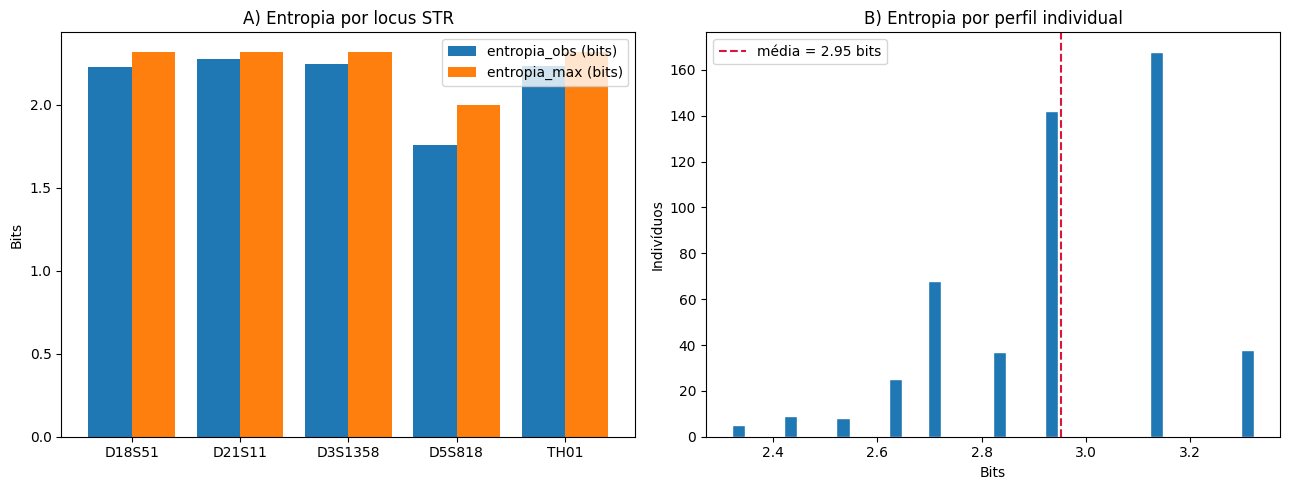

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Painel A: entropia observada vs. máxima por locus
entropia_por_locus[["entropia_obs (bits)", "entropia_max (bits)"]].plot.bar(
    ax=ax1, width=0.8, rot=0
)
ax1.set_title("A) Entropia por locus STR")
ax1.set_ylabel("Bits")
ax1.set_xlabel("")

# Painel B: entropia por indivíduo (perfil completo, concatenação)
entropia_individual = [
    entropia_shannon([a for locus_par in p.values() for a in locus_par])
    for p in perfis[:500]  # amostra de 500 para agilidade
]
ax2.hist(entropia_individual, bins=40, edgecolor="white")
ax2.axvline(np.mean(entropia_individual), color="crimson", ls="--",
            label=f"média = {np.mean(entropia_individual):.2f} bits")
ax2.set_title("B) Entropia por perfil individual")
ax2.set_xlabel("Bits"); ax2.set_ylabel("Indivíduos")
ax2.legend()

plt.tight_layout()

# Salva automaticamente na estrutura padronizada
figura = RAIZ / "results" / "figures" / "01_entropia_str.png"
plt.savefig(figura, dpi=300, bbox_inches="tight")
print(f"Figura salva em: {figura}")
plt.show()

## 4. Leitura dos resultados

- Locus com menor eficiência: **D5S818 (88%)** — candidato a exclusão do painel
- Entropia agregada (teórica): **~10.75 bits de alelos / ~22 bits de genótipos**
- Entropia observada por perfil (empírica): **2.95 bits médios**
- ⚠️ Observação crítica: discrepância entre entropia teórica (22 bits) e observada (2.95 bits)
  sugere heterogeneidade na distribuição de genótipos — material para discussão metodológica
- Comparativo com AES-128: fator de 6–40x abaixo (depende da métrica usada)